## Joint BiLSTM-CRF baseline (intent classification + slot filling)

### The two tasks (solved jointly by one model in each stage)

| Task | What is predicted | Model output | Metric |
|------|-------------------|--------------|--------|
| **Task 1: Intent classification** | One of 60 intent labels per utterance (e.g. `alarm_set`) | Intent head (pooled sentence vector → 60 logits) | Intent accuracy (%) |
| **Task 2: Slot filling** | The set of `[slot type : slot span]` pairs (55 slot types, e.g. `[time : five am]`) | Slot head (per-token BIO emissions → CRF) | Slot micro-F1 (%) |

### The two stages

| Stage | Notebook part | System |
|-------|---------------|--------|
| **Stage 1: baseline** | **Part A**, sections 1–14 | Joint BiLSTM-CRF |
| **Stage 2: AI-enhanced** | **Part B**, sections 15–22 | 3-member BiLSTM-CRF ensemble with character features |


---
# Part A: Stage 1 baseline (Task 1 + Task 2)

## 1. Imports and configuration

In [15]:
import os, re, math, copy, time, zipfile, io, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torchcrf import CRF

# Loads python packages for natural language processing
import nltk
from nltk.stem import WordNetLemmatizer
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

True

Loading the dataset file located in data folder. If it doesn't exist please import it

Additionally, GloVe 6B comes in four sizes (50,100,200,300)

Largest size is choosen for best performance

In [16]:
DATASET_FILE = "en-US.jsonl"

# Load the dataset file
DATA_FOLDER = "data"
MODEL_FOLDER = "model"
os.makedirs(MODEL_FOLDER, exist_ok=True)
if not os.path.exists(os.path.join(DATA_FOLDER, DATASET_FILE)):
    raise FileNotFoundError(f"Could not find {os.path.join(DATA_FOLDER, DATASET_FILE)}")
print("Using dataset at:", os.path.join(DATA_FOLDER, DATASET_FILE))

SEED = 4002
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Configuration parameters for the model
EMB_DIM_WANTED = 300   # GloVe 6B dimension
HIDDEN         = 256
NUM_LAYERS     = 2
DROPOUT        = 0.3
LR             = 1e-3
WEIGHT_DECAY   = 0.01
LABEL_SMOOTH   = 0.1
WORD_DROPOUT   = 0.25
BATCH_SIZE     = 32
NUM_EPOCHS     = 40
PATIENCE       = 8
GRAD_CLIP      = 5.0

print("Device:", device)

Using dataset at: data/en-US.jsonl
Device: cpu


## 2. Dataset and splits

Load `en-US.jsonl` and split it by the official `partition` field: **training** = `train` (11,514),
**validation** = `dev` (2,033), **test** = `test` (2,974). The input is `utt`. The **Task 1** label is
`intent` and the **Task 2** label is parsed from `annot_utt`.

In [17]:
df = pd.read_json(os.path.join(DATA_FOLDER, DATASET_FILE), lines=True)

assert (df["partition"] == "train").sum() == 11514
assert (df["partition"] == "dev").sum()   == 2033
assert (df["partition"] == "test").sum()  == 2974
print("Dataset shape:", df.shape, "| split sizes asserted")

train_df = df[df["partition"] == "train"].copy()
val_df   = df[df["partition"] == "dev"].copy()
test_df  = df[df["partition"] == "test"].copy()

x_train, y_train = train_df["utt"].tolist(), train_df["intent"].tolist()
x_val,   y_val   = val_df["utt"].tolist(),   val_df["intent"].tolist()
print("Training examples:  ", len(train_df))
print("Validation examples:", len(val_df))
print("Test examples:      ", len(test_df))

Dataset shape: (16521, 8) | split sizes asserted
Training examples:   11514
Validation examples: 2033
Test examples:       2974


## 3. Word vectors

Load the pre-trained **GloVe 6B** word embeddings from the local `glove.6B.zip` in the project folder.

In [18]:
zip_path = "glove.6B.zip"

if os.path.exists(zip_path):
    glove = {}
    with zipfile.ZipFile(zip_path) as z, z.open(f"glove.6B.{EMB_DIM_WANTED}d.txt") as f:
        for line in io.TextIOWrapper(f, encoding="utf-8"):
            word, *values = line.rstrip().split(" ")
            glove[word] = np.asarray(values, dtype=np.float32)
    print(f"Loaded GloVe {EMB_DIM_WANTED}d from {zip_path} | vocabulary size: {len(glove)}")
else:
    print(f"{zip_path} not found in the project folder")

Loaded GloVe 300d from glove.6B.zip | vocabulary size: 400001


## 4. Tokenization, vocabulary and lemmatization

Utterances are lowercased and split into word and punctuation tokens. Unseen words can optionally fall back to their WordNet lemma before mapping to `<UNK>`.

In [19]:
token_pattern = re.compile(r'\w+|[^\w\s]')
PAD_TOKEN, UNK_TOKEN = "<PAD>", "<UNK>"
PAD_ID, UNK_ID = 0, 1
SLOT_PAD_ID = -100


def tokenize_with_offsets(text):
    return [(m.group().lower(), m.start(), m.end()) for m in token_pattern.finditer(text)]


def tokenize(text):
    return [t for t, _, _ in tokenize_with_offsets(text)]


lemmatizer = WordNetLemmatizer()


def lemmatize_token(token):
    # Try the noun form first (plurals), then the verb form (tenses)
    lemma = lemmatizer.lemmatize(token, pos='n')
    if lemma == token:
        lemma = lemmatizer.lemmatize(token, pos='v')
    return lemma


def token_to_id(token, word_to_id, use_lemma):
    # Known words keep their own ID; only unseen words fall back to their lemma
    if token in word_to_id:
        return word_to_id[token]
    if use_lemma:
        lemma = lemmatize_token(token)
        if lemma in word_to_id:
            return word_to_id[lemma]
    return UNK_ID

## 5. Label preparation: Task 1 intents and Task 2 slot alignment

- **Task 1:** each `intent` string is mapped to a class ID (60 classes).
- **Task 2:** the `[slot type : span]` annotations in `annot_utt` are aligned to the tokens as BIO tags
  (111 tags = `O` + B-/I- for each of the 55 slot types).

In [20]:
slot_pattern = re.compile(r'\[\s*([^:\[\]]+?)\s*:\s*([^\[\]]*?)\]')


def parse_annotated_utterance(utt, annot_utt):
    spans, plain_text, last_end = [], '', 0
    for match in slot_pattern.finditer(annot_utt):
        plain_text += annot_utt[last_end:match.start()]
        slot_type, slot_value = match.group(1).strip(), match.group(2)
        start = len(plain_text)
        plain_text += slot_value
        spans.append({'type': slot_type, 'start': start,
                      'end': len(plain_text), 'text': slot_value})
        last_end = match.end()
    plain_text += annot_utt[last_end:]
    if plain_text != utt:
        raise ValueError(f"Slot annotation does not match utterance: {utt!r}")
    return spans


def make_aligned_tokens(utt, spans):
    tags, offsets, prev_slot = [], [], None
    for word, start, end in tokenize_with_offsets(utt):
        current_slot = None
        for i, span in enumerate(spans):
            if start < span['end'] and end > span['start']:
                if start < span['start'] or end > span['end']:
                    raise ValueError(f"A token cuts across a slot boundary: {utt!r}")
                current_slot = i
        if current_slot is None:
            tags.append('O')
        else:
            prefix = 'I' if current_slot == prev_slot else 'B'
            tags.append(f"{prefix}-{spans[current_slot]['type']}")
        offsets.append((start, end))
        prev_slot = current_slot
    return tags, offsets


def prepare_joint_records(split_df):
    records = []
    for row_index, row in split_df.iterrows():
        text = row['utt']
        spans = parse_annotated_utterance(text, row['annot_utt'])
        tags, offsets = make_aligned_tokens(text, spans)
        tokens = tokenize(text)
        if len(tokens) != len(tags):
            raise ValueError(f"Token and slot lengths differ at row {row_index}")
        records.append({'source_row': int(row_index), 'utt': text, 'tokens': tokens,
                        'offsets': offsets, 'gold_spans': spans,
                        'slot_tags': tags, 'intent': row['intent']})
    return records


train_records = prepare_joint_records(train_df)
val_records   = prepare_joint_records(val_df)
test_records  = prepare_joint_records(test_df)

intents = sorted(set(y_train))
intent_to_id = {v: i for i, v in enumerate(intents)}
num_classes = len(intent_to_id)

training_slot_types = sorted({s['type'] for r in train_records for s in r['gold_spans']})
slot_tags = ['O']
for t in training_slot_types:
    slot_tags.extend([f'B-{t}', f'I-{t}'])
slot_to_id = {tag: i for i, tag in enumerate(slot_tags)}
id_to_slot = {i: tag for tag, i in slot_to_id.items()}
num_slot_labels = len(slot_to_id)

max_len = max(64, max(len(r['tokens']) for r in train_records))
assert num_classes == 60 and num_slot_labels == 111
print('Intent classes:', num_classes, '| BIO labels:', num_slot_labels, '| max_len:', max_len)

Intent classes: 60 | BIO labels: 111 | max_len: 64


## 6. Dataset, loaders and the helpers the comparison needs

In [21]:
class JointNLUDataset(Dataset):
    def __init__(self, records, word_to_id, intent_to_id, slot_to_id, max_len, use_lemma=False):
        self.records = records
        self.input_ids, self.attention_masks = [], []
        self.intent_ids, self.slot_ids = [], []
        for row in records:
            words = [token_to_id(w, word_to_id, use_lemma) for w in row['tokens']]
            slots = [slot_to_id[tag] for tag in row['slot_tags']]
            if len(words) > max_len:
                raise ValueError(f"Sentence has {len(words)} tokens, limit is {max_len}")
            padding = max_len - len(words)
            self.input_ids.append(torch.tensor(words + [PAD_ID] * padding))
            self.attention_masks.append(
                torch.tensor([1] * len(words) + [0] * padding, dtype=torch.bool))
            self.intent_ids.append(torch.tensor(intent_to_id[row['intent']]))
            self.slot_ids.append(torch.tensor(slots + [SLOT_PAD_ID] * padding))

    def __len__(self):
        return len(self.records)

    def __getitem__(self, i):
        row = self.records[i]
        return {'input_ids': self.input_ids[i], 'attention_mask': self.attention_masks[i],
                'intent_labels': self.intent_ids[i], 'slot_labels': self.slot_ids[i],
                'utt': row['utt'], 'offsets': row['offsets'],
                'gold_spans': row['gold_spans'], 'source_row': row['source_row']}


def joint_collate_fn(samples):
    batch = {}
    for key in ('input_ids', 'attention_mask', 'intent_labels', 'slot_labels'):
        batch[key] = torch.stack([item[key] for item in samples])
    for key in ('utt', 'offsets', 'gold_spans', 'source_row'):
        batch[key] = [item[key] for item in samples]
    return batch


def build_vocab(records):
    # Vocabulary from the given training records only
    vocab = {PAD_TOKEN: PAD_ID, UNK_TOKEN: UNK_ID}
    for word in sorted({t for row in records for t in row['tokens']}):
        vocab[word] = len(vocab)
    return vocab


def build_embedding_matrix(vocab):
    matrix_rng = np.random.default_rng(SEED)
    matrix = matrix_rng.normal(0, 0.1, (len(vocab), EMB_DIM_WANTED)).astype(np.float32)
    matrix[PAD_ID] = 0
    for word, idx in vocab.items():
        if word in glove:
            matrix[idx] = glove[word]
    return matrix


def make_loader(records, vocab, use_lemma=False, shuffle=False, batch_size=None):
    dataset = JointNLUDataset(records, vocab, intent_to_id, slot_to_id, max_len,
                              use_lemma=use_lemma)
    generator = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(dataset, batch_size=batch_size or BATCH_SIZE, shuffle=shuffle,
                      collate_fn=joint_collate_fn, generator=generator)


def lemmatize_records(records):
    # Lemmatize model input tokens only; utt, offsets and gold spans stay original,
    # so slot scoring on character spans is unaffected.
    return [{**row, 'tokens': [lemmatize_token(t) for t in row['tokens']]} for row in records]


def word_frequencies(records, vocab):
    counts = collections.Counter(t for row in records for t in row['tokens'])
    freq = torch.zeros(len(vocab))
    for w, i in vocab.items():
        freq[i] = counts.get(w, 0)
    return freq.to(device)


word_to_id = build_vocab(train_records)
embedding_matrix = build_embedding_matrix(word_to_id)
print("Vocabulary size:", len(word_to_id))
print("Training tokens missing from GloVe:",
      sum(w not in glove for w in word_to_id if w not in (PAD_TOKEN, UNK_TOKEN)))

Vocabulary size: 5146
Training tokens missing from GloVe: 181


## 7. Stage-1 model and shared evaluation functions (Task 1 and Task 2)

- **Inputs:** lower-cased regex tokens mapped to word IDs (training-split vocabulary; unseen words fall back
  to their WordNet lemma when the "with fallback" variant is used).
- **Embedding:** 300d, initialised from GloVe 6B (random for the 181 training words GloVe lacks), fine-tuned.
- **Encoder:** dropout → 2-layer BiLSTM, 256 units per direction, packed sequences.
- **Task 1 output (intent classification):** concat(max-pool, mean-pool) of BiLSTM states → linear → 60 intent logits.
- **Task 2 output (slot filling):** per-token linear emissions over 111 BIO tags → CRF (Viterbi decoding).
- **Loss (joint):** Task 1 intent cross-entropy (label smoothing 0.1) + Task 2 CRF negative log-likelihood.
- **Optimiser:** AdamW (lr 1e-3, weight decay 0.01), cosine annealing, gradient clipping 5,
  frequency-based word dropout to `<UNK>` (α = 0.25), batch size 32, ≤ 40 epochs with early stopping.

**Shared scoring (used by both stages):** predicted BIO tags are converted to character spans in the original `utt`.

- **Task 1:** intent accuracy = 100 × correct / utterances
- **Task 2:** slot micro-F1 = 100 × 2TP / (2TP + FP + FN) over exact `(slot type, span)` matches pooled across utterances

In [22]:
class JointBiLSTM(nn.Module):
    def __init__(self, embedding_matrix, num_intents, num_slots):
        super().__init__()
        vocab_size, d_model = embedding_matrix.shape
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=PAD_ID)
        self.embedding.weight.data.copy_(torch.as_tensor(embedding_matrix))
        self.lstm = nn.LSTM(d_model, HIDDEN, NUM_LAYERS, batch_first=True,
                            bidirectional=True, dropout=DROPOUT)
        self.dropout = nn.Dropout(DROPOUT)
        self.slot_classifier = nn.Linear(2 * HIDDEN, num_slots)
        self.intent_classifier = nn.Linear(4 * HIDDEN, num_intents)
        self.crf = CRF(num_slots, batch_first=True)

    def forward(self, input_ids, attention_mask):
        lengths = attention_mask.sum(dim=1)
        x = self.dropout(self.embedding(input_ids))
        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True,
                                      enforce_sorted=False)
        h, _ = self.lstm(packed)
        h, _ = pad_packed_sequence(h, batch_first=True, total_length=input_ids.size(1))
        h = self.dropout(h)
        m = attention_mask.unsqueeze(-1)
        max_pool = h.masked_fill(~m, float('-inf')).max(dim=1).values
        mean_pool = (h * m).sum(dim=1) / m.sum(dim=1).clamp(min=1)
        return self.intent_classifier(torch.cat([max_pool, mean_pool], dim=-1)), \
               self.slot_classifier(h)


def tags_to_spans(tags):
    spans, cur, start = set(), None, 0
    for i, t in enumerate(tags):
        if t == 'O':
            if cur:
                spans.add((cur, start, i))
                cur = None
        else:
            prefix, slot_type = t[:1], t[2:]
            if prefix == 'B' or cur != slot_type:
                if cur:
                    spans.add((cur, start, i))
                cur, start = slot_type, i
    if cur:
        spans.add((cur, start, len(tags)))
    return spans


def spans_to_char(spans, offsets):
    # Scoring on character spans keeps the metric independent of tokenization
    return {(t, offsets[s][0], offsets[e - 1][1]) for t, s, e in spans}


def gold_char_spans(gold_spans):
    return {(s['type'], s['start'], s['end']) for s in gold_spans}


def intent_accuracy(predicted, gold):
    """100 x correct intent predictions / number of utterances."""
    return 100 * sum(p == g for p, g in zip(predicted, gold)) / len(gold)


def slot_micro_f1(predicted_spans, gold_spans):
    """F1 on exact (slot type, span) matches pooled over utterances: 100 x 2TP / (2TP + FP + FN)."""
    tp = fp = fn = 0
    for pred, gold in zip(predicted_spans, gold_spans):
        tp += len(gold & pred)
        fp += len(pred - gold)
        fn += len(gold - pred)
    return 0.0 if tp == 0 else 100 * 2 * tp / (2 * tp + fp + fn)


assert tags_to_spans(['O','O','B-time','I-time']) == {('time', 2, 4)}
assert tags_to_spans(['I-time','I-time','O','I-date','B-date']) == \
       {('time',0,2), ('date',3,4), ('date',4,5)}
assert intent_accuracy(['a', 'b', 'c', 'd'], ['a', 'b', 'x', 'y']) == 50
assert slot_micro_f1([{('time', 0, 4), ('date', 5, 9)}], [{('time', 0, 4)}]) == 100 * 2 / 3
print('scoring self-tests passed')

scoring self-tests passed


### Training and evaluation functions

- `unpack`: moves a batch to the device, trims padding-only columns and (during training) applies word dropout to `<UNK>`.
- `compute_loss`: joint loss = Task 1 intent cross-entropy + Task 2 CRF negative log-likelihood.
- `train_one_epoch`: one pass over the training data with gradient clipping and a scheduler step per batch.
- `evaluate`: returns the loss, Task 1 intent accuracy and Task 2 slot micro-F1 on a given split.

In [23]:
def unpack(batch, freq=None, training=False):
    ids  = batch['input_ids'].to(device)
    mask = batch['attention_mask'].to(device)
    slots = batch['slot_labels'].to(device)
    T = int(mask.sum(dim=1).max())              # trim padding-only columns
    ids, mask, slots = ids[:, :T], mask[:, :T], slots[:, :T]
    if training and WORD_DROPOUT > 0 and freq is not None:
        p = WORD_DROPOUT / (WORD_DROPOUT + freq[ids])
        hit = (torch.rand_like(p) < p) & mask & (ids > UNK_ID)
        ids = torch.where(hit, torch.full_like(ids, UNK_ID), ids)
    return ids, mask, slots, batch['intent_labels'].to(device)


def compute_loss(model, intent_logits, emissions, mask, slots, intent):
    return F.cross_entropy(intent_logits, intent, label_smoothing=LABEL_SMOOTH) \
           - model.crf(emissions, slots.clamp(min=0), mask=mask, reduction='mean')


def train_one_epoch(model, loader, optimizer, scheduler, freq):
    model.train()
    total_loss, total = 0.0, 0
    for batch in loader:
        ids, mask, slots, intent = unpack(batch, freq, training=True)
        optimizer.zero_grad()
        intent_logits, emissions = model(ids, mask)
        loss = compute_loss(model, intent_logits, emissions, mask, slots, intent)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()
        if scheduler:
            scheduler.step()
        total_loss += loss.item() * ids.size(0)
        total += ids.size(0)
    return total_loss / total


def evaluate(model, loader):
    '''Returns (loss, intent accuracy, slot micro-F1) using the shared scoring functions.'''
    model.eval()
    total_loss, total = 0.0, 0
    pred_intents, gold_intents, pred_spans, gold_spans = [], [], [], []
    with torch.no_grad():
        for batch in loader:
            ids, mask, slots, intent = unpack(batch)
            intent_logits, emissions = model(ids, mask)
            total_loss += compute_loss(model, intent_logits, emissions, mask,
                                       slots, intent).item() * ids.size(0)
            total += ids.size(0)
            pred_intents += intent_logits.argmax(dim=1).tolist()
            gold_intents += intent.tolist()
            for path, offsets, gold in zip(model.crf.decode(emissions, mask=mask),
                                           batch['offsets'], batch['gold_spans']):
                pred_spans.append(spans_to_char(tags_to_spans([id_to_slot[i] for i in path]), offsets))
                gold_spans.append(gold_char_spans(gold))
    return (total_loss / total, intent_accuracy(pred_intents, gold_intents),
            slot_micro_f1(pred_spans, gold_spans))

## 8. Stage 1: the experiment runner

Each variant trains for up to 40 epochs (early stopping, patience 8). After every epoch the training loss,
validation loss, validation Task 1 intent accuracy / Task 2 slot F1 and elapsed time are recorded. Only the **training split** is used
for fitting. The checkpoint with the best combined score on the **validation split**,
(Task 1 intent accuracy + Task 2 slot F1) / 2, is saved.

In [24]:
def run_experiment(embedding_matrix, train_loader, val_loaders, train_records_for_freq,
                   vocab, prefix='bilstm'):
    torch.manual_seed(SEED)            # same starting weights for every variant
    model = JointBiLSTM(embedding_matrix, num_classes, num_slot_labels).to(device)
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    steps = math.ceil(len(train_loader.dataset) / BATCH_SIZE) * NUM_EPOCHS
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=steps)
    freq = word_frequencies(train_records_for_freq, vocab)

    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    assert total_params <= 20_000_000, f"parameter budget exceeded: {total_params:,}"
    print(f"Total parameters: {total_params:,} "
          f"({100*total_params/20_000_000:.1f}% of the 20M budget)")
    print(f"Trainable parameters: {trainable_params:,}")

    best = {label: {'score': -1.0, 'epoch': None, 'acc': None, 'f1': None, 'state': None}
            for label in val_loaders}
    history = []
    run_start = time.time()

    for epoch in range(1, NUM_EPOCHS + 1):
        start = time.time()
        train_loss = train_one_epoch(model, train_loader, optimizer, scheduler, freq)
        row = {'epoch': epoch, 'train_loss': train_loss}
        for label, loader in val_loaders.items():
            val_loss, acc, f1 = evaluate(model, loader)
            score = (acc + f1) / 2
            row[f'{label} val loss'] = val_loss
            row[f'{label} intent'] = acc
            row[f'{label} slot F1'] = f1
            if score > best[label]['score']:
                best[label] = {'score': score, 'epoch': epoch, 'acc': acc, 'f1': f1,
                               'state': copy.deepcopy(model.state_dict())}
        row['seconds'] = time.time() - start
        history.append(row)
        text = " | ".join(f"{l} val loss {row[f'{l} val loss']:.4f} "
                          f"{row[f'{l} intent']:.2f}%/{row[f'{l} slot F1']:.2f}%"
                          for l in val_loaders)
        print(f"Epoch {epoch:02d}/{NUM_EPOCHS} | Train Loss {train_loss:.4f} | "
              f"{text} | {row['seconds']:.1f}s", flush=True)
        if all(epoch - b['epoch'] >= PATIENCE for b in best.values()):
            print(f"Early stopping: no improvement for {PATIENCE} epochs")
            break

    print(f"Training time: {time.time() - run_start:.0f}s over {len(history)} epochs")
    results = {}
    for label, info in best.items():
        filename = os.path.join(MODEL_FOLDER, f"{prefix}_{label.lower().replace(' ', '_')}_best.pt")
        torch.save(info['state'], filename)
        results[label] = {'Best epoch': info['epoch'],
                          'Intent accuracy (%)': round(info['acc'], 2),
                          'Slot micro-F1 (%)': round(info['f1'], 2),
                          'Combined (%)': round(info['score'], 2),
                          'Epochs trained': len(history),
                          'Checkpoint': filename}
        print(f"{label}: best val intent {info['acc']:.2f}% slot F1 {info['f1']:.2f}% "
              f"at epoch {info['epoch']} -> {filename}")
    return model, history, results


all_results = {}

## 9. Stage 1: training variants 1 (Without fallback) and 2 (With fallback)

In [25]:
# Training inputs are identical with and without the fallback, so one model serves both
train_with_lemma = JointNLUDataset(train_records, word_to_id, intent_to_id, slot_to_id,
                                   max_len, use_lemma=True)
train_without = JointNLUDataset(train_records, word_to_id, intent_to_id, slot_to_id,
                                max_len, use_lemma=False)
assert all(torch.equal(a, b) for a, b in zip(train_without.input_ids,
                                             train_with_lemma.input_ids))
print("Verified: training token IDs are identical with and without the OOV fallback")

rescued = sum(t not in word_to_id and lemmatize_token(t) in word_to_id
              for row in val_records for t in row['tokens'])
print("Unseen validation tokens rescued by lemma fallback:", rescued)

base_model, base_history, base_results = run_experiment(
    embedding_matrix,
    make_loader(train_records, word_to_id, shuffle=True),
    {'Without fallback': make_loader(val_records, word_to_id, use_lemma=False,
                                     batch_size=64),
     'With fallback':    make_loader(val_records, word_to_id, use_lemma=True,
                                     batch_size=64)},
    train_records, word_to_id)
all_results.update(base_results)

Verified: training token IDs are identical with and without the OOV fallback
Unseen validation tokens rescued by lemma fallback: 62
Total parameters: 4,394,530 (22.0% of the 20M budget)
Trainable parameters: 4,394,530
Epoch 01/40 | Train Loss 9.5730 | Without fallback val loss 5.1393 55.19%/63.55% | With fallback val loss 5.1299 55.14%/63.32% | 14.6s
Epoch 02/40 | Train Loss 4.5122 | Without fallback val loss 3.6394 74.72%/73.99% | With fallback val loss 3.6281 74.91%/73.92% | 13.4s
Epoch 03/40 | Train Loss 3.3559 | Without fallback val loss 3.1668 78.55%/78.05% | With fallback val loss 3.1620 78.65%/77.93% | 13.3s
Epoch 04/40 | Train Loss 2.7240 | Without fallback val loss 2.9798 81.95%/78.69% | With fallback val loss 2.9752 82.19%/78.61% | 13.4s
Epoch 05/40 | Train Loss 2.3296 | Without fallback val loss 2.8650 83.03%/79.37% | With fallback val loss 2.8573 83.18%/79.43% | 13.3s
Epoch 06/40 | Train Loss 2.0491 | Without fallback val loss 2.8029 83.67%/80.17% | With fallback val loss 2

## 10. Stage 1: variant 3, full lemmatization

In [26]:
full_train_records = lemmatize_records(train_records)
full_val_records   = lemmatize_records(val_records)
full_word_to_id    = build_vocab(full_train_records)

print("Full-lemma vocabulary size:", len(full_word_to_id), "| original:", len(word_to_id))
print("Example:", train_records[0]['tokens'][:8])
print("      ->", full_train_records[0]['tokens'][:8])

full_model, full_history, full_results = run_experiment(
    build_embedding_matrix(full_word_to_id),
    make_loader(full_train_records, full_word_to_id, shuffle=True),
    {'Full lemmatization': make_loader(full_val_records, full_word_to_id, batch_size=64)},
    full_train_records, full_word_to_id)
all_results.update(full_results)

Full-lemma vocabulary size: 4348 | original: 5146
Example: ['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday']
      -> ['wake', 'me', 'up', 'at', 'nine', 'be', 'on', 'friday']
Total parameters: 4,155,130 (20.8% of the 20M budget)
Trainable parameters: 4,155,130
Epoch 01/40 | Train Loss 9.6235 | Full lemmatization val loss 5.1504 55.53%/62.68% | 12.4s
Epoch 02/40 | Train Loss 4.5516 | Full lemmatization val loss 3.7164 74.18%/72.51% | 12.7s
Epoch 03/40 | Train Loss 3.3559 | Full lemmatization val loss 3.1850 79.39%/77.95% | 11.9s
Epoch 04/40 | Train Loss 2.7428 | Full lemmatization val loss 2.9180 81.06%/79.21% | 11.9s
Epoch 05/40 | Train Loss 2.3216 | Full lemmatization val loss 2.8980 82.59%/78.76% | 11.9s
Epoch 06/40 | Train Loss 2.0573 | Full lemmatization val loss 2.7916 83.28%/80.21% | 12.0s
Epoch 07/40 | Train Loss 1.8321 | Full lemmatization val loss 2.7427 85.49%/80.41% | 12.0s
Epoch 08/40 | Train Loss 1.6801 | Full lemmatization val loss 2.7781 84.95%/80.71% | 11.9s
Epoc

## 11. Stage 1: comparison of variants (validation split) and selection

In [27]:
comparison = pd.DataFrame.from_dict(all_results, orient='index')
comparison.index.name = 'Variant'
print(comparison.to_string())

def best_variant_by(metric):
    # Name of the variant with the highest value of the given metric
    best_name = None
    for name in all_results:
        if best_name is None or all_results[name][metric] > all_results[best_name][metric]:
            best_name = name
    return best_name


best_variant = best_variant_by('Intent accuracy (%)')
print(f"\nBest intent accuracy: {best_variant} "
      f"({all_results[best_variant]['Intent accuracy (%)']:.2f}%)")
best_slot = best_variant_by('Slot micro-F1 (%)')
print(f"Best slot F1        : {best_slot} "
      f"({all_results[best_slot]['Slot micro-F1 (%)']:.2f}%)")

# The Stage-1 system is the variant with the best combined validation score
FINAL_VARIANT = best_variant_by('Combined (%)')
print(f"\nSelected Stage-1 system: {FINAL_VARIANT} "
      f"(combined validation score {all_results[FINAL_VARIANT]['Combined (%)']:.2f}%, "
      f"epoch {all_results[FINAL_VARIANT]['Best epoch']}, "
      f"checkpoint {all_results[FINAL_VARIANT]['Checkpoint']})")

                    Best epoch  Intent accuracy (%)  Slot micro-F1 (%)  Combined (%)  Epochs trained                         Checkpoint
Variant                                                                                                                                
Without fallback            14                85.93              81.40         83.66              22    bilstm_without_fallback_best.pt
With fallback               14                86.23              81.56         83.89              22       bilstm_with_fallback_best.pt
Full lemmatization          31                87.36              81.72         84.54              39  bilstm_full_lemmatization_best.pt

Best intent accuracy: Full lemmatization (87.36%)
Best slot F1        : Full lemmatization (81.72%)

Selected Stage-1 system: Full lemmatization (combined validation score 84.54%, epoch 31, checkpoint bilstm_full_lemmatization_best.pt)


## 12. Stage 1: learning curves

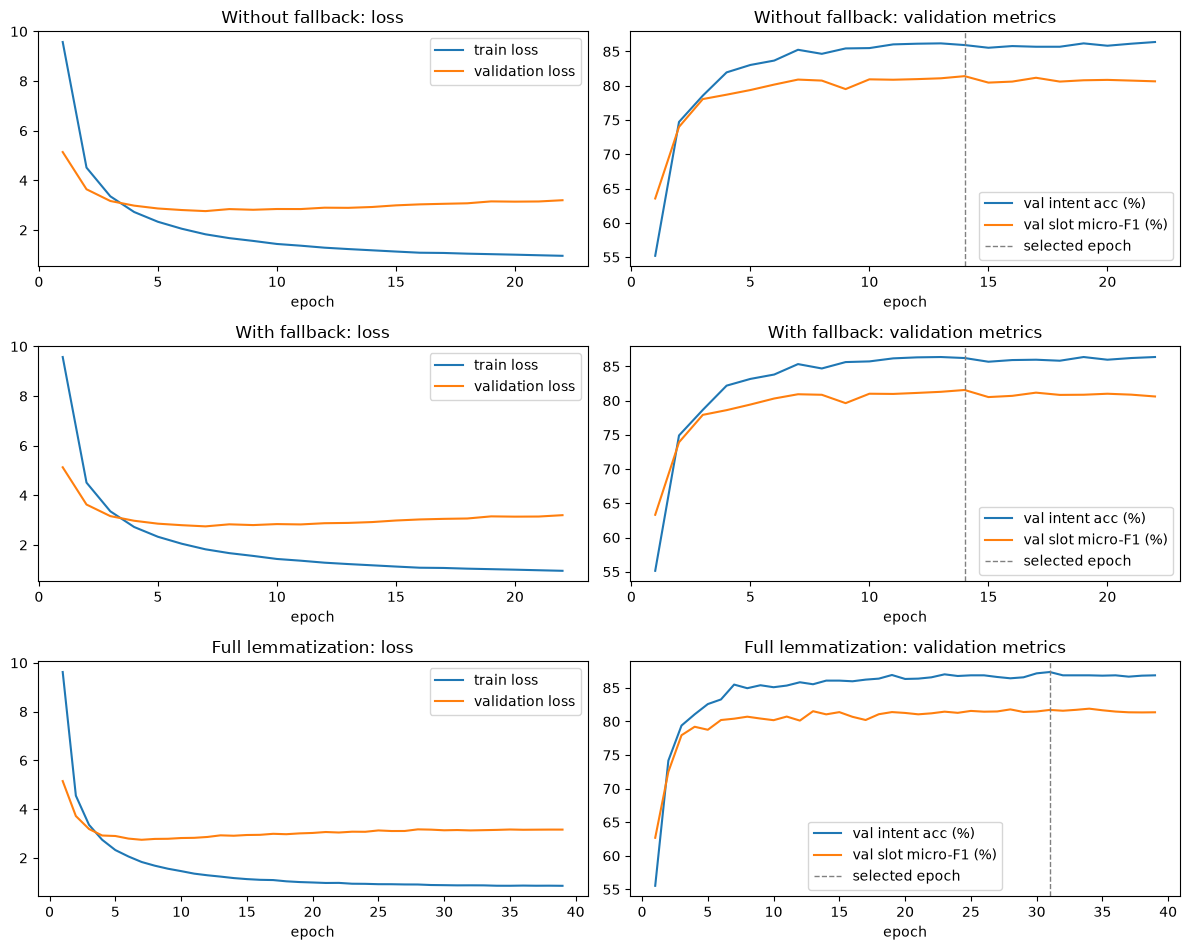


=== Without fallback ===
 epoch  train_loss  Without fallback val loss  Without fallback intent  Without fallback slot F1  seconds
     1      9.5730                     5.1393                  55.1894                   63.5490  14.6444
     2      4.5122                     3.6394                  74.7172                   73.9925  13.3543
     3      3.3559                     3.1668                  78.5539                   78.0537  13.3194
     4      2.7240                     2.9798                  81.9479                   78.6935  13.3653
     5      2.3296                     2.8650                  83.0300                   79.3722  13.2885
     6      2.0491                     2.8029                  83.6695                   80.1671  13.3227
     7      1.8241                     2.7591                  85.2435                   80.8972  13.3716
     8      1.6702                     2.8404                  84.6532                   80.7491  13.3392
     9      1.5582  

In [28]:
curves = [(label, pd.DataFrame(base_history)) for label in ('Without fallback', 'With fallback')] + \
         [('Full lemmatization', pd.DataFrame(full_history))]

fig, axes = plt.subplots(len(curves), 2, figsize=(12, 3.2 * len(curves)), squeeze=False)
for row, (label, h) in zip(axes, curves):
    row[0].plot(h['epoch'], h['train_loss'], label='train loss')
    row[0].plot(h['epoch'], h[f'{label} val loss'], label='validation loss')
    row[0].set_title(f'{label}: loss')
    row[0].set_xlabel('epoch')
    row[0].legend()
    row[1].plot(h['epoch'], h[f'{label} intent'], label='val intent acc (%)')
    row[1].plot(h['epoch'], h[f'{label} slot F1'], label='val slot micro-F1 (%)')
    row[1].axvline(all_results[label]['Best epoch'], color='grey', ls='--', lw=1,
                   label='selected epoch')
    row[1].set_title(f'{label}: validation metrics')
    row[1].set_xlabel('epoch')
    row[1].legend()
plt.tight_layout()
plt.show()

for label, h in curves:
    cols = ['epoch', 'train_loss', f'{label} val loss', f'{label} intent', f'{label} slot F1', 'seconds']
    print(f"\n=== {label} ===")
    print(h[cols].round(4).to_string(index=False))

## 13. Stage 1: final evaluation of the checkpoint (validation and test splits)

Load the selected checkpoint into a freshly built model (no further training), check that the
validation score matches the best validation score printed during training, then evaluate on the
**test split**. Both Task 1 (intent accuracy) and Task 2 (slot micro-F1) are reported.

In [29]:
def keep_records(records):
    # The fallback variants use the records unchanged
    return records


# How each variant turns records into model inputs
variant_setup = {
    'Without fallback':   dict(vocab=word_to_id, use_lemma=False, prepare=keep_records),
    'With fallback':      dict(vocab=word_to_id, use_lemma=True,  prepare=keep_records),
    'Full lemmatization': dict(vocab=full_word_to_id, use_lemma=False, prepare=lemmatize_records),
}
setup = variant_setup[FINAL_VARIANT]
checkpoint = all_results[FINAL_VARIANT]['Checkpoint']

stage1_model = JointBiLSTM(build_embedding_matrix(setup['vocab']), num_classes, num_slot_labels).to(device)
stage1_model.load_state_dict(torch.load(checkpoint, map_location=device))
total_params = sum(p.numel() for p in stage1_model.parameters())
trainable_params = sum(p.numel() for p in stage1_model.parameters() if p.requires_grad)
print(f"Loaded {checkpoint} ({FINAL_VARIANT}) | total parameters {total_params:,} | "
      f"trainable {trainable_params:,}")

final_val_loader = make_loader(setup['prepare'](val_records), setup['vocab'],
                               use_lemma=setup['use_lemma'], batch_size=64)
final_test_loader = make_loader(setup['prepare'](test_records), setup['vocab'],
                                use_lemma=setup['use_lemma'], batch_size=64)

_, val_acc, val_f1 = evaluate(stage1_model, final_val_loader)
print(f"Validation (reloaded): intent accuracy {val_acc:.2f}% | slot micro-F1 {val_f1:.2f}%")
assert round(val_acc, 2) == all_results[FINAL_VARIANT]['Intent accuracy (%)'] and \
       round(val_f1, 2) == all_results[FINAL_VARIANT]['Slot micro-F1 (%)'], \
       "reloaded validation score differs from the best validation score"
print("Matches the best validation score from training.")

_, test_acc, test_f1 = evaluate(stage1_model, final_test_loader)
print(f"\nTEST: intent accuracy {test_acc:.2f}% | slot micro-F1 {test_f1:.2f}%")

Loaded bilstm_full_lemmatization_best.pt (Full lemmatization) | total parameters 4,155,130 | trainable 4,155,130
Validation (reloaded): intent accuracy 87.36% | slot micro-F1 81.72%
Matches the best validation score from training.

TEST: intent accuracy 85.84% | slot micro-F1 79.41%


## 14. Stage 1: results table

In [30]:
best_epoch = all_results[FINAL_VARIANT]['Best epoch']
epochs_trained = all_results[FINAL_VARIANT]['Epochs trained']
stage1_table = pd.DataFrame([
    {'Model version': 'Stage-1 system', 'Split': split, 'Total # parameters': total_params,
     'Total # trainable parameters': trainable_params,
     'Intent accuracy (%)': f"{acc:.2f}", 'Slot micro-F1 (%)': f"{f1:.2f}",
     'Number of epochs': f"{best_epoch} (best of {epochs_trained})"}
    for split, acc, f1 in (('Validation', val_acc, val_f1), ('Test', test_acc, test_f1))])
stage1_table

,Model version,Split,Total # parameters,Total # trainable parameters,Intent accuracy (%),Slot micro-F1 (%),Number of epochs
0,Stage-1 system,Validation,4155130,4155130,87.36,81.72,31 (best of 39)
1,Stage-1 system,Test,4155130,4155130,85.84,79.41,31 (best of 39)


---
# Part B: Stage 2 AI-enhanced system (Task 1 + Task 2)

Built after collaborating with AI to diagnose the Stage-1 baseline. It reuses Stage 1's data splits,
tokenisation, BIO alignment, word vocabulary, GloVe vectors, lemma fallback and **shared scoring functions**.

| # | Change from Stage 1 | Why |
|---|---------------------|-----|
| 1 | Character-level CNN word features concatenated with GloVe | Handles unseen / misspelled words and morphology that word vectors map to `<UNK>` |
| 2 | **Task 1:** attention pooling added to max + mean pooling for intent | Lets the intent head focus on the few decisive words |
| 3 | **Task 2:** intent-aware slot emissions (pooled sentence vector concatenated to each token state) | Slot types depend on the intent (e.g. *time* vs *date*) |
| 4 | One-cycle LR schedule (10% warm-up, cosine decay) | More stable early training |
| 5 | GloVe frozen and shared by all ensemble members | Freezing did not hurt validation scores; one shared 1.54M table frees budget for an extra member |
| 6 | Heterogeneous 3-member ensemble: intent probabilities averaged; slot emissions and CRF transitions averaged before one Viterbi decode | Ensembling diverse models reduces variance; the whole system stays under 20M parameters |

Tried and rejected on validation (see report): intent-conditioned slot-type masking, stochastic weight
averaging / longer training, smaller (128-unit) members.

## 15. Stage 2: configuration and inputs

In [31]:
torch.set_num_threads(min(8, os.cpu_count()))
MAX_CHARS = 20

S2_BASE_CFG = dict(char=True, char_filters=100, hidden=256, layers=2, dropout=0.3, attn=True,
                   intent2slot=True, lr=1e-3, weight_decay=0.01, label_smoothing=0.1,
                   word_dropout=0.25, batch_size=32, epochs=30, patience=10, grad_clip=5.0)

S2_MEMBERS = [
    dict(name='word', seed=SEED, char=False, attn=False, intent2slot=False),  # Stage-1 architecture
    dict(name='full', seed=SEED),                                           # all Stage-2 changes
    dict(name='char', seed=SEED, attn=False, intent2slot=False),            # + character CNN only
]


def add_chars(records):
    # Original-case surface form of every token, for the character CNN
    return [{**r, 'chars': [r['utt'][s:e] for s, e in r['offsets']]} for r in records]


s2_train, s2_val, s2_test = (add_chars(r) for r in (train_records, val_records, test_records))
char_to_id = {c: i + 2 for i, c in enumerate(          # 0 = pad, 1 = unknown character
    sorted({c for r in s2_train for tok in r['chars'] for c in tok}))}


class CharJointDataset(Dataset):
    def __init__(self, records):
        self.records, self.items = records, []
        for r in records:
            words = torch.tensor([token_to_id(t, word_to_id, use_lemma=True) for t in r['tokens']])
            chars = torch.zeros(len(r['chars']), MAX_CHARS, dtype=torch.long)
            for i, tok in enumerate(r['chars']):
                ids = [char_to_id.get(ch, 1) for ch in tok[:MAX_CHARS]]
                chars[i, :len(ids)] = torch.tensor(ids)
            slots = torch.tensor([slot_to_id[t] for t in r['slot_tags']])
            self.items.append((words, chars, slots, intent_to_id[r['intent']]))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        # Return the index only; collate() builds the padded batch from self.items
        return i


def make_char_loader(dataset, batch_size, shuffle, seed=SEED):
    def collate(indices):                       # dynamic padding to the longest utterance
        L, B = max(len(dataset.items[i][0]) for i in indices), len(indices)
        w = torch.zeros(B, L, dtype=torch.long)
        c = torch.zeros(B, L, MAX_CHARS, dtype=torch.long)
        s = torch.full((B, L), SLOT_PAD_ID)
        m = torch.zeros(B, L, dtype=torch.bool)
        y = torch.zeros(B, dtype=torch.long)
        for b, i in enumerate(indices):
            wi, ci, si, yi = dataset.items[i]
            n = len(wi)
            w[b, :n] = wi
            c[b, :n] = ci
            s[b, :n] = si
            m[b, :n] = True
            y[b] = yi
        return {'words': w, 'chars': c, 'slots': s, 'mask': m, 'intent': y, 'index': indices}
    generator = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      collate_fn=collate, generator=generator)


s2_train_ds, s2_val_ds, s2_test_ds = (CharJointDataset(r) for r in (s2_train, s2_val, s2_test))
s2_val_loader  = make_char_loader(s2_val_ds, 128, shuffle=False)
s2_test_loader = make_char_loader(s2_test_ds, 128, shuffle=False)
print("Character vocabulary:", len(char_to_id) + 2)
print("Example:", s2_train[0]['chars'], s2_train[0]['slot_tags'])

Character vocabulary: 34
Example: ['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday'] ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date']


## 16. Stage 2: model (Task 1 and Task 2)

- **Inputs:** word IDs (frozen GloVe 300d, one table shared by all members) and per-token character IDs.
- **Encoder:** `[GloVe ; CharCNN(50d chars, 100 filters, width 3, max-pool)]` → dropout →
  2-layer BiLSTM (256 per direction).
- **Task 1 output (intent head):** concat(max-pool, mean-pool, attention-pool) → linear → 60 intents.
- **Task 2 output (slot head):** each BiLSTM state concatenated with a tanh projection of the pooled sentence vector
  → linear emissions over 111 BIO tags → CRF.
- **Loss (joint):** Task 1 intent cross-entropy (label smoothing 0.1) + Task 2 CRF negative log-likelihood.
- **Optimiser:** AdamW (lr 1e-3, weight decay 0.01), one-cycle schedule, gradient clipping 5, word dropout α = 0.25.

Members switch off some components (`S2_MEMBERS`) for diversity. At inference the ensemble averages Task 1 intent
probabilities, and averages Task 2 slot emissions and CRF transition scores before a single Viterbi decode
(equivalent to adding the members' path scores).

In [32]:
class CharCNN(nn.Module):
    def __init__(self, num_chars, char_dim=50, filters=100, width=3):
        super().__init__()
        self.embedding = nn.Embedding(num_chars, char_dim, padding_idx=0)
        self.conv = nn.Conv1d(char_dim, filters, width, padding=width // 2)

    def forward(self, chars):                                   # (B, L, C)
        B, L, C = chars.shape
        flat = chars.view(B * L, C)
        x = self.conv(self.embedding(flat).transpose(1, 2))     # (B*L, filters, C)
        x = x.masked_fill((flat == 0).unsqueeze(1), -1e4).max(dim=2).values
        word_exists = (chars[:, :, 0] != 0).unsqueeze(-1)
        return x.clamp(min=-1e3).view(B, L, -1) * word_exists


class JointBiLSTMv2(nn.Module):
    def __init__(self, embedding, cfg):
        super().__init__()
        self.cfg = cfg
        self.embedding = embedding                  # shared, frozen GloVe table
        in_dim = embedding.embedding_dim
        if cfg['char']:
            self.char_cnn = CharCNN(len(char_to_id) + 2, filters=cfg['char_filters'])
            in_dim += cfg['char_filters']
        H = cfg['hidden']
        self.lstm = nn.LSTM(in_dim, H, cfg['layers'], batch_first=True,
                            bidirectional=True, dropout=cfg['dropout'])
        self.dropout = nn.Dropout(cfg['dropout'])
        pool_dim = 4 * H
        if cfg['attn']:
            self.attention = nn.Linear(2 * H, 1)
            pool_dim += 2 * H
        self.intent_classifier = nn.Linear(pool_dim, num_classes)
        slot_in = 2 * H
        if cfg['intent2slot']:
            self.intent_to_slot = nn.Linear(pool_dim, 2 * H)
            slot_in += 2 * H
        self.slot_classifier = nn.Linear(slot_in, num_slot_labels)
        self.crf = CRF(num_slot_labels, batch_first=True)

    def forward(self, words, chars, mask):
        x = self.embedding(words)
        if self.cfg['char']:
            x = torch.cat([x, self.char_cnn(chars)], dim=-1)
        x = self.dropout(x)
        packed = pack_padded_sequence(x, mask.sum(1).cpu(), batch_first=True, enforce_sorted=False)
        h, _ = self.lstm(packed)
        h, _ = pad_packed_sequence(h, batch_first=True, total_length=words.size(1))
        h = self.dropout(h)
        m = mask.unsqueeze(-1)
        pools = [h.masked_fill(~m, -1e4).max(dim=1).values, (h * m).sum(1) / m.sum(1)]
        if self.cfg['attn']:
            weights = self.attention(h).masked_fill(~m, -1e4).softmax(dim=1)
            pools.append((weights * h).sum(1))
        sentence = torch.cat(pools, dim=-1)
        intent_logits = self.intent_classifier(sentence)
        if self.cfg['intent2slot']:
            context = torch.tanh(self.intent_to_slot(sentence))
            h = torch.cat([h, context.unsqueeze(1).expand(-1, h.size(1), -1)], dim=-1)
        return intent_logits, self.slot_classifier(h)


shared_embedding = nn.Embedding.from_pretrained(
    torch.as_tensor(build_embedding_matrix(word_to_id)), freeze=True, padding_idx=PAD_ID).to(device)


def build_member(cfg):
    torch.manual_seed(cfg['seed'])
    return JointBiLSTMv2(shared_embedding, cfg).to(device)


def count_params(models):
    # Shared parameters (the GloVe table) are counted once for the whole system
    unique = {id(p): p for m in models for p in m.parameters()}.values()
    return sum(p.numel() for p in unique), sum(p.numel() for p in unique if p.requires_grad)


_preview = [build_member(dict(S2_BASE_CFG, **m)) for m in S2_MEMBERS]
for m, model in zip(S2_MEMBERS, _preview):
    print(f"{m['name']:>8}: {count_params([model])[1]:,} trainable parameters")
print(f"Shared frozen GloVe table: {shared_embedding.weight.numel():,} parameters")
S2_TOTAL, S2_TRAINABLE = count_params(_preview)
print(f"Total parameters (whole ensemble, incl. word vectors): {S2_TOTAL:,}")
print(f"Total trainable parameters:                            {S2_TRAINABLE:,}")
assert S2_TOTAL <= 20_000_000, "parameter budget exceeded"
print(f"Within budget: {100 * S2_TOTAL / 20_000_000:.1f}% of 20M")
del _preview

    word: 2,850,730 trainable parameters
    full: 3,947,339 trainable parameters
    char: 3,072,330 trainable parameters
Shared frozen GloVe table: 1,543,800 parameters
Total parameters (whole ensemble, incl. word vectors): 11,414,199
Total trainable parameters:                            9,870,399
Within budget: 57.1% of 20M


## 17. Stage 2: loss, ensemble inference and evaluation (shared scoring functions)

In [33]:
s2_word_freq = word_frequencies(train_records, word_to_id)


def joint_loss(model, intent_logits, emissions, batch, label_smoothing):
    return F.cross_entropy(intent_logits, batch['intent'], label_smoothing=label_smoothing) \
           - model.crf(emissions, batch['slots'].clamp(min=0), mask=batch['mask'], reduction='mean')


def validation_loss(model, loader):
    model.eval()
    total, n = 0.0, 0
    with torch.no_grad():
        for b in loader:
            il, em = model(b['words'], b['chars'], b['mask'])
            total += joint_loss(model, il, em, b, 0.0).item() * len(b['intent'])
            n += len(b['intent'])
    return total / n


def predict_ensemble(models, loader, records):
    """Returns (intent labels, predicted character spans, intent probabilities)."""
    for m in models:
        m.eval()
    k = len(models)
    crf = models[0].crf
    pred_intents, pred_spans, all_probs = [], [], []
    with torch.no_grad():
        for b in loader:
            # Sum the members' intent probabilities, slot emissions and CRF transition scores
            probs = emissions = trans = start = end = 0
            for m in models:
                il, em = m(b['words'], b['chars'], b['mask'])
                probs = probs + il.softmax(-1)
                emissions = emissions + em
                trans = trans + m.crf.transitions
                start = start + m.crf.start_transitions
                end = end + m.crf.end_transitions

            # Decode once with the averaged CRF, then restore the first member's CRF
            saved_trans = crf.transitions.data.clone()
            saved_start = crf.start_transitions.data.clone()
            saved_end = crf.end_transitions.data.clone()
            crf.transitions.data = trans / k
            crf.start_transitions.data = start / k
            crf.end_transitions.data = end / k
            paths = crf.decode(emissions / k, mask=b['mask'])
            crf.transitions.data = saved_trans
            crf.start_transitions.data = saved_start
            crf.end_transitions.data = saved_end

            for i, path, p in zip(b['index'], paths, probs / k):
                pred_intents.append(intents[int(p.argmax())])
                pred_spans.append(spans_to_char(tags_to_spans([id_to_slot[t] for t in path]),
                                                records[i]['offsets']))
                all_probs.append(p)
    return pred_intents, pred_spans, torch.stack(all_probs)


def evaluate_ensemble(models, loader, records):
    pi, ps, _ = predict_ensemble(models, loader, records)
    acc = intent_accuracy(pi, [r['intent'] for r in records])
    f1 = slot_micro_f1(ps, [gold_char_spans(r['gold_spans']) for r in records])
    return {'intent_acc': acc, 'slot_f1': f1, 'combined': (acc + f1) / 2}

## 18. Stage 2: train the ensemble members (training split only)

Each member keeps the weights from its epoch with the best combined score on the validation split,
(Task 1 intent accuracy + Task 2 slot F1) / 2.

In [34]:
def train_member(cfg):
    model = build_member(cfg)
    torch.manual_seed(cfg['seed'])
    np.random.seed(cfg['seed'])
    train_loader = make_char_loader(s2_train_ds, cfg['batch_size'], shuffle=True, seed=cfg['seed'])
    optimizer = optim.AdamW([p for p in model.parameters() if p.requires_grad],
                            lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=cfg['lr'], pct_start=0.1,
                                              total_steps=len(train_loader) * cfg['epochs'])
    best, history = {'combined': -1.0}, []
    run_start = time.time()
    for epoch in range(1, cfg['epochs'] + 1):
        model.train()
        start, total, n = time.time(), 0.0, 0
        for b in train_loader:
            words = b['words']
            if cfg['word_dropout'] > 0:   # replace rare words by <UNK> to learn an UNK representation
                p = cfg['word_dropout'] / (cfg['word_dropout'] + s2_word_freq[words])
                hit = (torch.rand_like(p) < p) & b['mask'] & (words > UNK_ID)
                words = torch.where(hit, torch.full_like(words, UNK_ID), words)
            intent_logits, emissions = model(words, b['chars'], b['mask'])
            loss = joint_loss(model, intent_logits, emissions, b, cfg['label_smoothing'])
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg['grad_clip'])
            optimizer.step()
            scheduler.step()
            total += loss.item() * len(b['intent'])
            n += len(b['intent'])
        val = evaluate_ensemble([model], s2_val_loader, s2_val)
        row = {'epoch': epoch, 'train_loss': total / n,
               'val_loss': validation_loss(model, s2_val_loader),
               'val_intent_acc': val['intent_acc'], 'val_slot_f1': val['slot_f1'],
               'val_combined': val['combined'], 'seconds': time.time() - start}
        history.append(row)
        print(f"[{cfg['name']}] Epoch {epoch:02d}/{cfg['epochs']} | train loss {row['train_loss']:.4f} | "
              f"val loss {row['val_loss']:.4f} | val intent {val['intent_acc']:.2f}% | "
              f"val slot F1 {val['slot_f1']:.2f}% | {row['seconds']:.1f}s", flush=True)
        if val['combined'] > best['combined']:
            best = {**val, 'epoch': epoch, 'state': copy.deepcopy(model.state_dict())}
        if epoch - best['epoch'] >= cfg['patience']:
            print(f"[{cfg['name']}] early stopping")
            break
    model.load_state_dict(best['state'])
    print(f"[{cfg['name']}] best epoch {best['epoch']} | val intent {best['intent_acc']:.2f}% | "
          f"val slot F1 {best['slot_f1']:.2f}% | training time {time.time() - run_start:.0f}s\n")
    return model, best, pd.DataFrame(history)


members, member_best, member_history = [], {}, {}
overall_start = time.time()
for m in S2_MEMBERS:
    cfg = dict(S2_BASE_CFG, **m)
    model, best, history = train_member(cfg)
    members.append(model)
    member_best[cfg['name']] = best
    member_history[cfg['name']] = history
print(f"Total Stage-2 training time: {(time.time() - overall_start) / 60:.1f} min")

[word] Epoch 01/30 | train loss 18.8679 | val loss 11.7232 | val intent 10.53% | val slot F1 2.81% | 14.3s
[word] Epoch 02/30 | train loss 9.4977 | val loss 6.1263 | val intent 48.06% | val slot F1 48.37% | 14.2s
[word] Epoch 03/30 | train loss 5.7362 | val loss 3.7986 | val intent 65.52% | val slot F1 67.43% | 14.2s
[word] Epoch 04/30 | train loss 4.1965 | val loss 2.9765 | val intent 76.34% | val slot F1 73.34% | 14.3s
[word] Epoch 05/30 | train loss 3.4113 | val loss 2.6560 | val intent 79.00% | val slot F1 76.42% | 14.2s
[word] Epoch 06/30 | train loss 2.9182 | val loss 2.3716 | val intent 81.36% | val slot F1 77.62% | 14.2s
[word] Epoch 07/30 | train loss 2.5567 | val loss 2.2618 | val intent 83.13% | val slot F1 77.91% | 14.2s
[word] Epoch 08/30 | train loss 2.3046 | val loss 2.1697 | val intent 84.06% | val slot F1 79.47% | 15.0s
[word] Epoch 09/30 | train loss 2.0776 | val loss 2.1407 | val intent 84.46% | val slot F1 79.04% | 16.0s
[word] Epoch 10/30 | train loss 1.9039 | val 

## 19. Stage 2: epoch-level logs and learning curves


=== word ===
 epoch  train_loss  val_loss  val_intent_acc  val_slot_f1  val_combined  seconds
     1     18.8679   11.7232         10.5263       2.8105        6.6684  14.2607
     2      9.4977    6.1263         48.0571      48.3688       48.2129  14.2381
     3      5.7362    3.7986         65.5189      67.4346       66.4767  14.2173
     4      4.1965    2.9765         76.3404      73.3402       74.8403  14.3156
     5      3.4113    2.6560         78.9966      76.4228       77.7097  14.1647
     6      2.9182    2.3716         81.3576      77.6187       79.4881  14.2056
     7      2.5567    2.2618         83.1284      77.9124       80.5204  14.2457
     8      2.3046    2.1697         84.0630      79.4742       81.7686  15.0062
     9      2.0776    2.1407         84.4565      79.0387       81.7476  15.9667
    10      1.9039    2.0918         84.4073      80.3804       82.3938  14.8659
    11      1.7670    2.0972         84.5548      80.4108       82.4828  14.7713
    12      1.

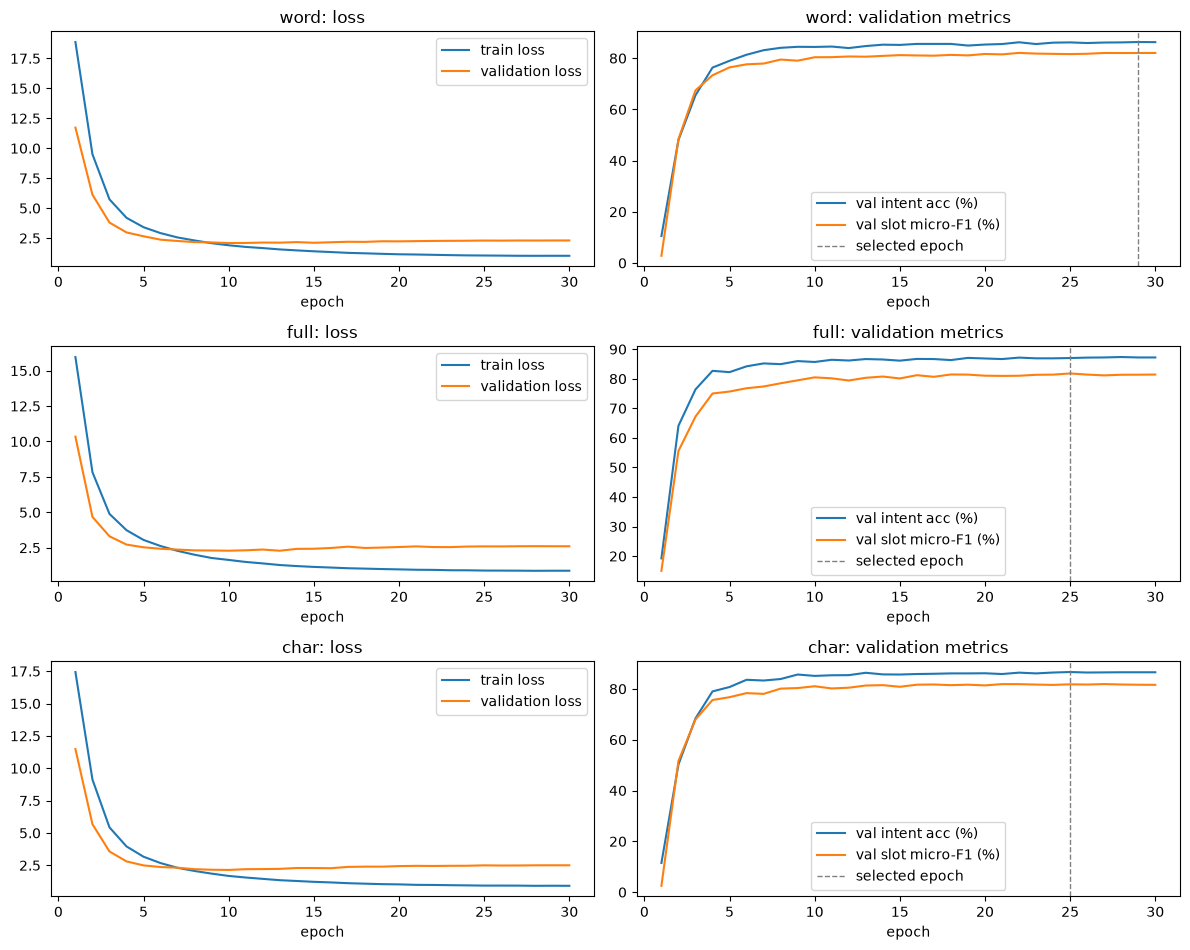

In [35]:
for name, h in member_history.items():
    print(f"\n=== {name} ===")
    print(h.round(4).to_string(index=False))

fig, axes = plt.subplots(len(member_history), 2, figsize=(12, 3.2 * len(member_history)), squeeze=False)
for row, (name, h) in zip(axes, member_history.items()):
    row[0].plot(h['epoch'], h['train_loss'], label='train loss')
    row[0].plot(h['epoch'], h['val_loss'], label='validation loss')
    row[0].set_title(f'{name}: loss')
    row[0].set_xlabel('epoch')
    row[0].legend()
    row[1].plot(h['epoch'], h['val_intent_acc'], label='val intent acc (%)')
    row[1].plot(h['epoch'], h['val_slot_f1'], label='val slot micro-F1 (%)')
    row[1].axvline(member_best[name]['epoch'], color='grey', ls='--', lw=1, label='selected epoch')
    row[1].set_title(f'{name}: validation metrics')
    row[1].set_xlabel('epoch')
    row[1].legend()
plt.tight_layout()
plt.show()

## 20. Stage 2: select and save the checkpoint (validation split)

In [36]:
S2_CHECKPOINT = os.path.join(MODEL_FOLDER, "stage2_ensemble_best.pt")
ensemble_val = evaluate_ensemble(members, s2_val_loader, s2_val)

torch.save({'members': [dict(S2_BASE_CFG, **m) for m in S2_MEMBERS],
            'states': [member_best[m['name']]['state'] for m in S2_MEMBERS],
            'best_epochs': {k: v['epoch'] for k, v in member_best.items()},
            'val_scores': ensemble_val}, S2_CHECKPOINT)

for name, b in member_best.items():
    print(f"{name:>8}: best epoch {b['epoch']:2d} | val intent {b['intent_acc']:.2f}% | "
          f"val slot F1 {b['slot_f1']:.2f}%")
print(f"\nEnsemble validation: intent accuracy {ensemble_val['intent_acc']:.2f}% | "
      f"slot micro-F1 {ensemble_val['slot_f1']:.2f}% | combined {ensemble_val['combined']:.2f}%")
print("Checkpoint saved to:", S2_CHECKPOINT)

    word: best epoch 29 | val intent 86.33% | val slot F1 82.04%
    full: best epoch 25 | val intent 87.01% | val slot F1 81.80%
    char: best epoch 25 | val intent 86.62% | val slot F1 81.78%

Ensemble validation: intent accuracy 87.65% | slot micro-F1 83.31% | combined 85.48%
Checkpoint saved to: stage2_ensemble_best.pt


## 21. Stage 2: final evaluation of the checkpoint (validation and test splits)

Reload the saved checkpoint into freshly built models (no further training), check the validation score
matches the one above, then evaluate once on the **test split**.
Both Task 1 (intent accuracy) and Task 2 (slot micro-F1) are reported.

In [37]:
ckpt = torch.load(S2_CHECKPOINT)
loaded = []
for cfg, state in zip(ckpt['members'], ckpt['states']):
    model = build_member(cfg)
    model.load_state_dict(state)
    loaded.append(model.eval())
s2_total, s2_trainable = count_params(loaded)
print(f"Loaded {len(loaded)} members | total parameters {s2_total:,} | trainable {s2_trainable:,}")

s2_val_scores = evaluate_ensemble(loaded, s2_val_loader, s2_val)
print(f"Validation (reloaded): intent accuracy {s2_val_scores['intent_acc']:.2f}% | "
      f"slot micro-F1 {s2_val_scores['slot_f1']:.2f}%")
assert abs(s2_val_scores['combined'] - ckpt['val_scores']['combined']) < 1e-9, \
    "reloaded validation score differs from the saved one"
print("Matches the saved best validation score.")

s2_test_intents, s2_test_spans, s2_test_probs = predict_ensemble(loaded, s2_test_loader, s2_test)
s2_test_acc = intent_accuracy(s2_test_intents, [r['intent'] for r in s2_test])
s2_test_f1 = slot_micro_f1(s2_test_spans, [gold_char_spans(r['gold_spans']) for r in s2_test])
print(f"\nTEST: intent accuracy {s2_test_acc:.2f}% | slot micro-F1 {s2_test_f1:.2f}%")

Loaded 3 members | total parameters 11,414,199 | trainable 9,870,399
Validation (reloaded): intent accuracy 87.65% | slot micro-F1 83.31%
Matches the saved best validation score.

TEST: intent accuracy 86.52% | slot micro-F1 80.74%


## 22. Results: Stage 1 vs Stage 2 (report table) and Stage-2 error analysis

The error analysis lists Task 1 (intent) errors first, then Task 2 (slot) errors, on the test split.

In [38]:
pd.set_option('display.max_colwidth', None)
s2_epochs = ", ".join(f"{k}: {v}" for k, v in ckpt['best_epochs'].items())
stage2_table = pd.DataFrame([
    {'Model version': 'Stage-2 system', 'Split': split, 'Total # parameters': s2_total,
     'Total # trainable parameters': s2_trainable,
     'Intent accuracy (%)': f"{acc:.2f}", 'Slot micro-F1 (%)': f"{f1:.2f}",
     'Number of epochs': f"best per member: {s2_epochs}"}
    for split, acc, f1 in (('Validation', s2_val_scores['intent_acc'], s2_val_scores['slot_f1']),
                           ('Test', s2_test_acc, s2_test_f1))])
final_table = pd.concat([stage1_table, stage2_table], ignore_index=True)
final_table

,Model version,Split,Total # parameters,Total # trainable parameters,Intent accuracy (%),Slot micro-F1 (%),Number of epochs
0,Stage-1 system,Validation,4155130,4155130,87.36,81.72,31 (best of 39)
1,Stage-1 system,Test,4155130,4155130,85.84,79.41,31 (best of 39)
2,Stage-2 system,Validation,11414199,9870399,87.65,83.31,"best per member: word: 29, full: 25, char: 25"
3,Stage-2 system,Test,11414199,9870399,86.52,80.74,"best per member: word: 29, full: 25, char: 25"


In [39]:
intent_errors = [(r['utt'], r['intent'], p, float(prob.max()))
                 for r, p, prob in zip(s2_test, s2_test_intents, s2_test_probs) if p != r['intent']]
print(f"Intent errors: {len(intent_errors)} / {len(s2_test)}")
confusions = collections.Counter((g, p) for _, g, p, _ in intent_errors)
print("\nMost frequent intent confusions (gold -> predicted):")
for (g, p), n in confusions.most_common(10):
    print(f"  {n:3d}  {g} -> {p}")
print("\nSample intent errors:")
for utt, g, p, conf in intent_errors[:8]:
    print(f"  {utt!r}\n      gold {g} | pred {p} (p={conf:.2f})")

def format_spans(spans, utt):
    # Show (type, start, end) spans as readable "[type: text]" strings
    return sorted(f"[{t}: {utt[s:e]}]" for t, s, e in spans)


slot_errors = []
type_fn, type_fp = collections.Counter(), collections.Counter()
for r, pred in zip(s2_test, s2_test_spans):
    gold = gold_char_spans(r['gold_spans'])
    for slot_type, start, end in gold - pred:
        type_fn[slot_type] += 1
    for slot_type, start, end in pred - gold:
        type_fp[slot_type] += 1
    if gold != pred:
        slot_errors.append((r['utt'], format_spans(gold - pred, r['utt']),
                            format_spans(pred - gold, r['utt'])))
print(f"\nUtterances with at least one slot error: {len(slot_errors)} / {len(s2_test)}")
print("Slot types with most missed (FN) / spurious (FP) spans:")
type_errors = type_fn + type_fp
for t, _ in type_errors.most_common(10):
    print(f"  {t:<20} FN {type_fn[t]:3d} | FP {type_fp[t]:3d}")
print("\nSample slot errors:")
for utt, missed, spurious in slot_errors[:8]:
    print(f"  {utt!r}\n      missed {missed} | spurious {spurious}")

Intent errors: 401 / 2974

Most frequent intent confusions (gold -> predicted):
   17  general_quirky -> qa_factoid
   13  general_quirky -> calendar_query
   12  qa_factoid -> general_quirky
    8  calendar_set -> calendar_query
    7  news_query -> general_quirky
    7  general_quirky -> news_query
    6  play_radio -> play_music
    5  general_quirky -> weather_query
    5  qa_definition -> general_quirky
    4  transport_query -> general_quirky

Sample intent errors:
  'pink is all we need'
      gold iot_hue_lightchange | pred play_music (p=0.19)
  'and the darkness has fallen'
      gold iot_hue_lighton | pred qa_factoid (p=0.29)
  "it's dirty here make some noise"
      gold iot_cleaning | pred play_music (p=0.44)
  'hoover the hallway'
      gold iot_cleaning | pred email_querycontact (p=0.29)
  'send a giggle my way'
      gold general_joke | pred general_quirky (p=0.56)
  'i feel like jazz right now how about you'
      gold play_music | pred music_likeness (p=0.77)
  'what i